In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
print("Importing complete")

Importing complete


In [2]:
np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False) 

### Use NumPy arrays from the score and attendance columns. Print both arrays and display:

Data type
Number of dimensions
Shape
Total number of elements

In [3]:
print(student_scores)
print(f"Students scores data type: {student_scores.dtype}")
print(f"Students scores dymensions: {student_scores.ndim}") 
print(f"Students scores shape: {student_scores.shape}")  
print(f"Students scores Total number of elements: {student_scores.size}")

[76 90 46 60 48 78 57 43 64 99 53 89 97 48 65 92 41 59 67 86 99 46 83 47
 86 74 53 56 75 89 79 43 41 45 93 81 43 93 68 57 65 83 73 49 75 53 70 87
 54 47]
Students scores data type: int32
Students scores dymensions: 1
Students scores shape: (50,)
Students scores Total number of elements: 50


In [4]:
print(student_attendance)
print(f"Students attandence data type: {student_attendance.dtype}")
print(f"Students attandence dymensions: {student_attendance.ndim}") 
print(f"Students attandence shape: {student_attendance.shape}")  
print(f"Students attandence Total number of elements: {student_attendance.size}")

[73 82 99 80 75 77 83 85 84 88 74 60 84 66 68 83 60 67 83 70 76 67 94 94
 92 64 98 87 66 68 67 71 93 92 82 83 96 94 99 81 86 94 60 94 96 73 62 60
 64 85]
Students attandence data type: int32
Students attandence dymensions: 1
Students attandence shape: (50,)
Students attandence Total number of elements: 50


### Using NumPy functions on :
Find the maximum and minimum score
Calculate the average score
Calculate the average attendance
Then, extract students who:

Have a score greater than the average score
#### Print:

The filtered score array

In [5]:
print("Maximum score", student_scores.max())
print("Minimum score", student_scores.min()) 

avg_score = student_scores.mean()
avg_attendance = student_attendance.mean()
print("Average attendance", avg_attendance)

print("Average score", avg_score)

ans = student_scores[student_scores > avg_score]
print(ans)

Maximum score 99
Minimum score 41
Average attendance 79.58
Average score 67.3
[76 90 78 99 89 97 92 86 99 83 86 74 75 89 79 93 81 93 68 83 73 75 70 87]


### Load the school_data.csv file into a Pandas DataFrame.

Display the first 3 rows
Show dataset information using .info()
Display summary statistics using .describe()
Then filter the dataset to include only:

student_id, student_age, department, grade
### Select students whose age is between 16 and 20, sort them by student_id, and display the last 3 rows of the result.

In [6]:
df = pd.read_csv("school_data.csv")

df.head(3)

,student_id,student_age,score,attendance,department,grade
0,201,21,76,73,Physics,B
1,202,18,90,82,Physics,A
2,203,19,46,99,Biology,F


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   student_id   50 non-null     int64 
 1   student_age  50 non-null     int64 
 2   score        50 non-null     int64 
 3   attendance   50 non-null     int64 
 4   department   50 non-null     object
 5   grade        50 non-null     object
dtypes: int64(4), object(2)
memory usage: 2.5+ KB


In [8]:
df.describe()

,student_id,student_age,score,attendance
count,50.00000,50.000000,50.000000,50.000000
mean,225.50000,18.280000,67.300000,79.580000
std,14.57738,1.852081,18.248008,12.163998
min,201.00000,15.000000,41.000000,60.000000
25%,213.25000,17.000000,50.000000,68.000000
50%,225.50000,18.000000,66.000000,82.000000
75%,237.75000,20.000000,83.000000,91.000000
max,250.00000,21.000000,99.000000,99.000000


In [9]:
age_between_16_20 = df.loc[(df['student_age'] <= 20) & (df['student_age'] >= 16)].sort_values('student_id')
age_between_16_20[['student_id', 'student_age', 'department', 'grade']].tail(3)

,student_id,student_age,department,grade
45,246,18,Biology,C
47,248,18,Science,A
49,250,17,Economics,F


Using .loc:

Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
Increase the score by 5% for all other departments
Cap the score at 100 (no score should exceed 100 after the raise)
Then print a DataFrame that includes:

student_id, department, previous_score, new_score, score_increase

In [10]:
df['previous_score'] = df['score']

csm_dept = df['department'].isin(["Computer Science", "Mathematics"])

df.loc[csm_dept, 'score'] = (df.loc[csm_dept, 'score'] * 1.1).clip(upper=100)

df.loc[~csm_dept, 'score'] = (df.loc[~csm_dept, 'score'] * 1.05).clip(upper=100) 

df['score_increase'] = df['score'] - df['previous_score']

ans = df[['student_id', 'department', 'previous_score', 'score', 'score_increase']]
ans = ans.rename(columns={'score': 'new_score'})

print(ans)

    student_id        department  previous_score  new_score  score_increase
0          201           Physics              76      79.80            3.80
1          202           Physics              90      94.50            4.50
2          203           Biology              46      48.30            2.30
3          204         Economics              60      63.00            3.00
4          205         Economics              48      50.40            2.40
5          206              Arts              78      81.90            3.90
6          207           Physics              57      59.85            2.85
7          208           Science              43      45.15            2.15
8          209  Computer Science              64      70.40            6.40
9          210  Computer Science              99     100.00            1.00
10         211       Mathematics              53      58.30            5.30
11         212           Physics              89      93.45            4.45
12         2

C:\Users\Nazmul Hasan\AppData\Local\Temp\ipykernel_30208\3565561366.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[ 70.4 100.   58.3  52.8 100.   91.3  47.3  74.8  77. ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[csm_dept, 'score'] = (df.loc[csm_dept, 'score'] * 1.1).clip(upper=100)


In [11]:
df

,student_id,student_age,score,attendance,department,grade,previous_score,score_increase
0,201,21,79.80,73,Physics,B,76,3.80
1,202,18,94.50,82,Physics,A,90,4.50
2,203,19,48.30,99,Biology,F,46,2.30
3,204,21,63.00,80,Economics,C,60,3.00
4,205,17,50.40,75,Economics,F,48,2.40
5,206,19,81.90,77,Arts,B,78,3.90
6,207,19,59.85,83,Physics,C,57,2.85
7,208,21,45.15,85,Science,F,43,2.15
8,209,16,70.40,84,Computer Science,C,64,6.40
9,210,17,100.00,88,Computer Science,A,99,1.00


In [12]:
df.columns

Index(['student_id', 'student_age', 'score', 'attendance', 'department',
       'grade', 'previous_score', 'score_increase'],
      dtype='object')

Using Matplotlib, create a bar chart that shows the average score per department.

X-axis: Department names
Y-axis: Average score
Add a title: "Average Score by Department"
Display the chart

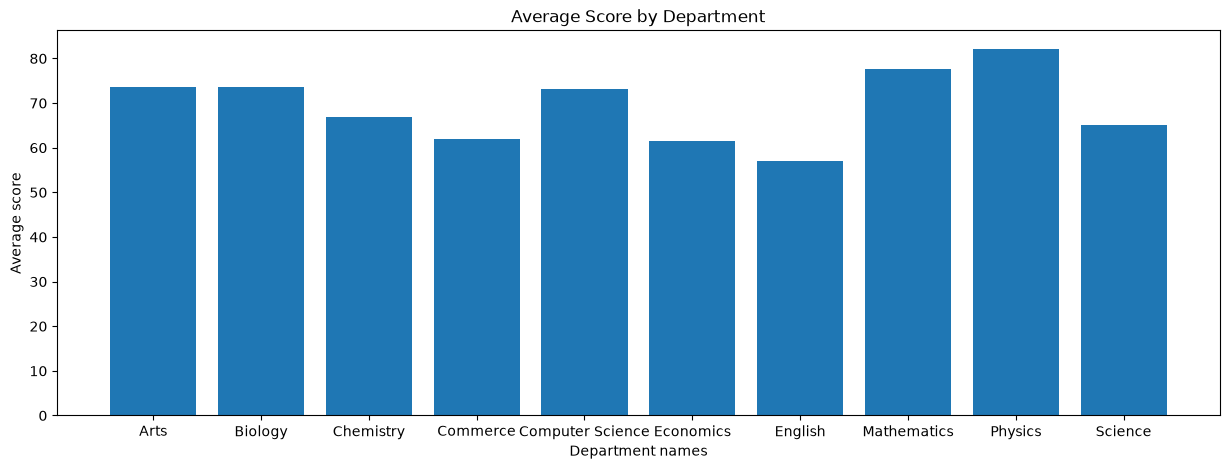

In [13]:
avg_score_per_department = df.groupby('department', as_index=False)['score'].mean()

plt.figure(figsize=(15, 5))

plt.bar(avg_score_per_department['department'], avg_score_per_department['score'])

plt.title("Average Score by Department")
plt.xlabel("Department names")
plt.ylabel("Average score")

plt.show()

Using Matplotlib, create a histogram of the score column.

Use 10 bins
Add a title: "Distribution of Student Scores"
Label X-axis as "Score" and Y-axis as "Number of Students"
Display the chart

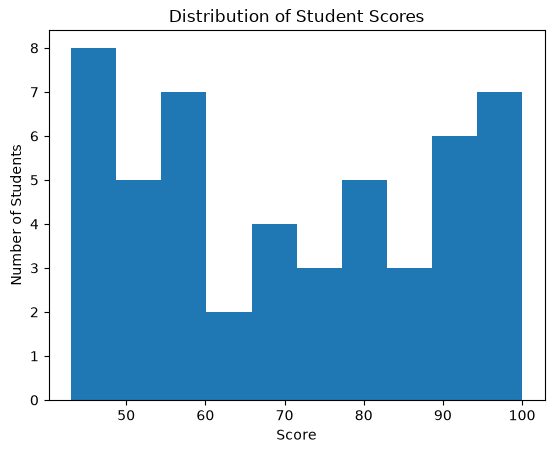

In [14]:
plt.hist(df['score'], bins=10)
plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of Students")
plt.show()

Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

X-axis: Attendance (%)
Y-axis: Score
Add a title: "Attendance vs Score"
Label both axes properly
Display the chart

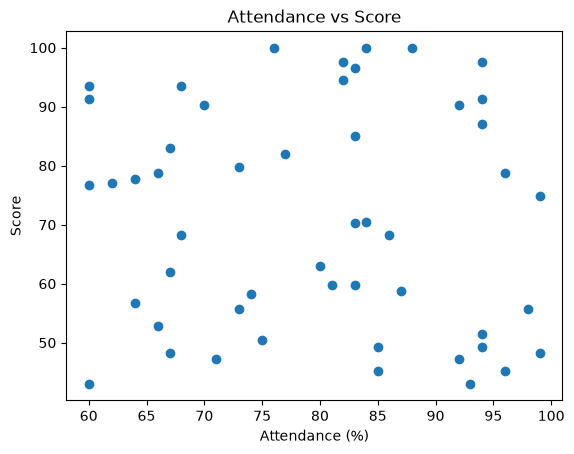

In [15]:
plt.scatter(df['attendance'], df['score'])
plt.title("Attendance vs Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")
plt.show()

Using Seaborn, create a boxplot / barplot that shows the distribution of score across different grade categories.

X-axis: Grade
Y-axis: Score
Add a title: "Score Distribution by Grade"
Display the chart

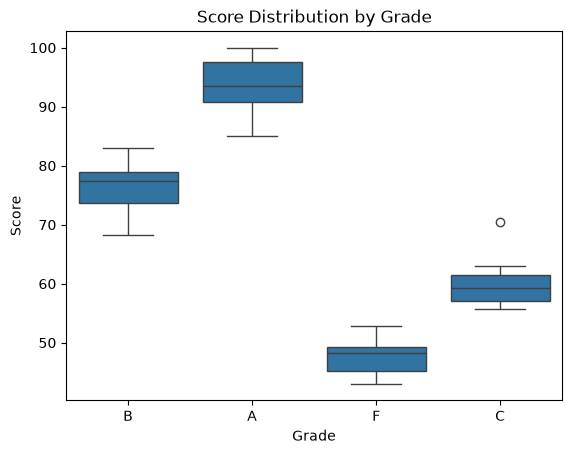

In [16]:
sns.boxplot(data=df, x='grade', y='score')

plt.title("Score Distribution by Grade")
plt.xlabel("Grade")
plt.ylabel("Score")
plt.show()

Using Seaborn, create a countplot showing the number of students in each department.

Add a title: "Number of Students per Department"
Display the chart

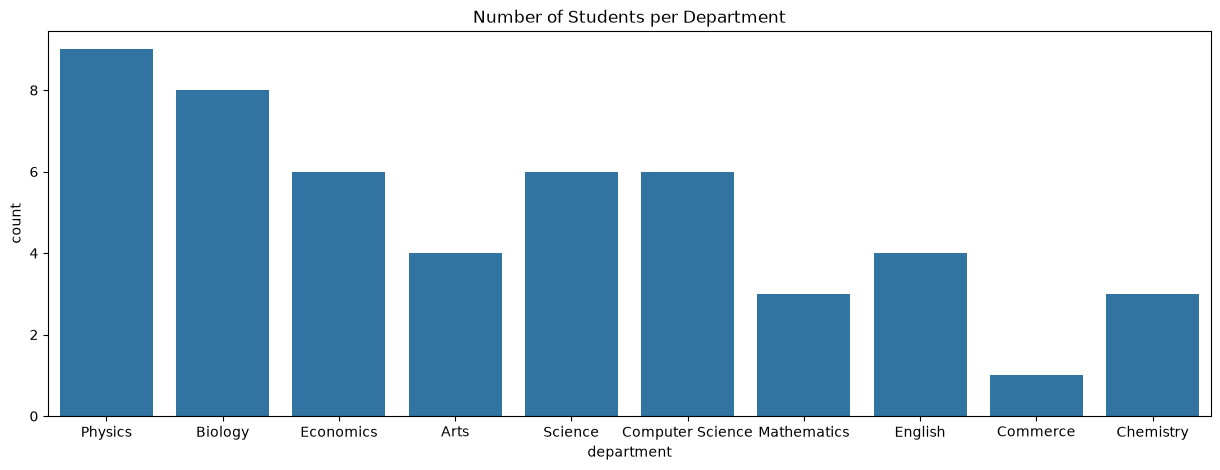

In [17]:
plt.figure(figsize=(15, 5)) 
sns.countplot(data=df, x='department')

plt.title("Number of Students per Department")
plt.show()

In [18]:
df.columns

Index(['student_id', 'student_age', 'score', 'attendance', 'department',
       'grade', 'previous_score', 'score_increase'],
      dtype='object')

In [19]:
len(df[df['department'] == "Physics"])


9

create a scatter plot showing attendance vs score.

Color the points by department
Add a title: "Attendance vs Score by Department"
Label X-axis as "Attendance (%)" and Y-axis as "Score"
Display the chart

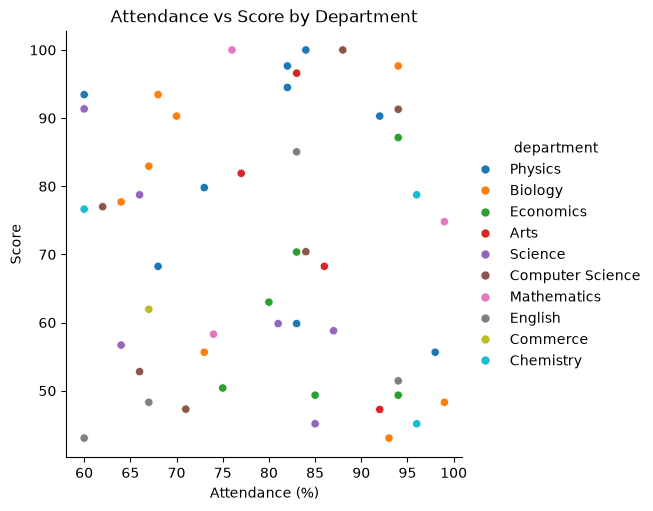

In [20]:
sns.relplot(kind='scatter', data=df, x='attendance', y='score', hue='department')

plt.title("Attendance vs Score by Department")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")
plt.show()